In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import(accuracy_score,precision_score,recall_score,f1_score,classification_report,
                            confusion_matrix,ConfusionMatrixDisplay)

In [2]:
df= pd.read_excel('Raisin_Dataset.xlsx')
df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


In [3]:
df.tail()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
895,83248,430.077308,247.838695,0.817263,85839,0.668793,1129.072,Besni
896,87350,440.735698,259.293149,0.808629,90899,0.636476,1214.252,Besni
897,99657,431.706981,298.837323,0.721684,106264,0.741099,1292.828,Besni
898,93523,476.344094,254.176054,0.845739,97653,0.658798,1258.548,Besni
899,85609,512.081774,215.271976,0.907345,89197,0.632020,1272.862,Besni


In [4]:
df.shape

(900, 8)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             900 non-null    int64  
 1   MajorAxisLength  900 non-null    float64
 2   MinorAxisLength  900 non-null    float64
 3   Eccentricity     900 non-null    float64
 4   ConvexArea       900 non-null    int64  
 5   Extent           900 non-null    float64
 6   Perimeter        900 non-null    float64
 7   Class            900 non-null    str    
dtypes: float64(5), int64(2), str(1)
memory usage: 61.7 KB


In [6]:
df.isnull().sum()

Area               0
MajorAxisLength    0
MinorAxisLength    0
Eccentricity       0
ConvexArea         0
Extent             0
Perimeter          0
Class              0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df=df.drop_duplicates()

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
# Encode raisin class labels as numeric values
label_encoder=LabelEncoder()
df["Class_encoded"]=label_encoder.fit_transform(df["Class"])
print("Class label encoding preview:")
print(df[["Class","Class_encoded"]].head(5))

Class label encoding preview:
     Class  Class_encoded
0  Kecimen              1
1  Kecimen              1
2  Kecimen              1
3  Kecimen              1
4  Kecimen              1


In [11]:
# Select numeric columns as model features
numerical_features = df.select_dtypes(include=np.number).columns

In [12]:
# Separate features and labels, then create stratified training and test sets
X = df[numerical_features]
y = df["Class_encoded"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

In [13]:
# Create a Gaussian Naive Bayes classifier
GaussianNB()

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


In [14]:
# Train the Gaussian Naive Bayes classifier

gnb= GaussianNB()
gnb.fit(X_train,y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


In [15]:
# Predict raisin classes for the test set

y_pred=gnb.predict(X_test)
print("Predicted class labels:", label_encoder.inverse_transform(y_pred))

Predicted class labels: ['Kecimen' 'Besni' 'Besni' 'Kecimen' 'Besni' 'Kecimen' 'Besni' 'Kecimen'
 'Kecimen' 'Kecimen' 'Kecimen' 'Kecimen' 'Kecimen' 'Kecimen' 'Besni'
 'Kecimen' 'Kecimen' 'Kecimen' 'Besni' 'Besni' 'Besni' 'Kecimen' 'Kecimen'
 'Kecimen' 'Kecimen' 'Kecimen' 'Kecimen' 'Kecimen' 'Kecimen' 'Kecimen'
 'Kecimen' 'Kecimen' 'Besni' 'Besni' 'Kecimen' 'Besni' 'Kecimen' 'Besni'
 'Besni' 'Besni' 'Besni' 'Besni' 'Besni' 'Besni' 'Besni' 'Besni' 'Besni'
 'Kecimen' 'Besni' 'Besni' 'Kecimen' 'Kecimen' 'Besni' 'Kecimen' 'Kecimen'
 'Kecimen' 'Besni' 'Kecimen' 'Besni' 'Besni' 'Besni' 'Kecimen' 'Kecimen'
 'Besni' 'Besni' 'Kecimen' 'Besni' 'Kecimen' 'Kecimen' 'Kecimen' 'Kecimen'
 'Besni' 'Besni' 'Kecimen' 'Kecimen' 'Kecimen' 'Besni' 'Kecimen' 'Besni'
 'Kecimen' 'Besni' 'Kecimen' 'Kecimen' 'Kecimen' 'Kecimen' 'Besni'
 'Kecimen' 'Kecimen' 'Kecimen' 'Kecimen' 'Besni' 'Kecimen' 'Kecimen'
 'Besni' 'Kecimen' 'Kecimen' 'Kecimen' 'Kecimen' 'Kecimen' 'Besni'
 'Kecimen' 'Kecimen' 'Kecimen' 'Besni' 'Kec

In [16]:
# Compare actual and predicted encoded labels
comparison=pd.DataFrame({"Actual":y_test.values,"Predicted":y_pred})
print("Actual and predicted encoded labels (first 5 rows):")
print(comparison.head(5))

Actual and predicted encoded labels (first 5 rows):
   Actual  Predicted
0       0          1
1       0          0
2       0          0
3       1          1
4       0          0


In [17]:
# Convert encoded predictions to class names for comparison
comparison["Actual Class"]=label_encoder.inverse_transform(comparison["Actual"])
comparison["Predicted Class"]=label_encoder.inverse_transform(comparison["Predicted"])
print("Actual and predicted class names (first 5 rows):")
print(comparison.head(5))

Actual and predicted class names (first 5 rows):
   Actual  Predicted Actual Class Predicted Class
0       0          1        Besni         Kecimen
1       0          0        Besni           Besni
2       0          0        Besni           Besni
3       1          1      Kecimen         Kecimen
4       0          0        Besni           Besni


In [18]:
# Calculate and display test-set accuracy
accuracy=accuracy_score(y_test,y_pred)
print(f"Test accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")

Test accuracy: 0.8278 (82.78%)


In [19]:
# Calculate and display test-set precision
precision=precision_score(y_test,y_pred)
print(f"Precision: {precision:.4f}")

Precision: 0.7658


In [20]:
# Calculate and display test-set F1 score
f1=f1_score(y_test,y_pred)
print(f"F1 score: {f1:.4f}")

F1 score: 0.8458


In [21]:
# Calculate and display the test-set confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix (rows: actual classes, columns: predicted classes):")
print(cm)

Confusion matrix (rows: actual classes, columns: predicted classes):
[[64 26]
 [ 5 85]]


In [22]:
# Compare classifier accuracy on training and test sets
from sklearn.metrics import accuracy_score

y_train_pred=gnb.predict(X_train)
y_test_pred=gnb.predict(X_test)

train_accuracy=accuracy_score(y_train,y_train_pred)
test_accuracy=accuracy_score(y_test,y_test_pred)

print(f"Training accuracy: {train_accuracy:.4f} ({train_accuracy*100:.2f}%)")
print(f"Testing accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")

Training accuracy: 0.8375 (83.75%)
Testing accuracy: 0.8278 (82.78%)


In [23]:
# Display the Gaussian Naive Bayes model configuration
GaussianNB(priors=None)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


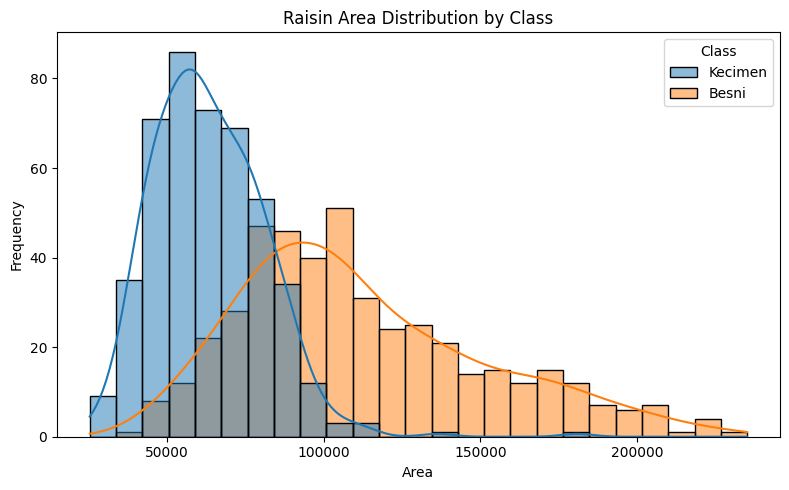

In [24]:
# Plot raisin area distributions by class with a histogram
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Area", hue="Class", kde=True, bins=25)
plt.title("Raisin Area Distribution by Class")
plt.xlabel("Area")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

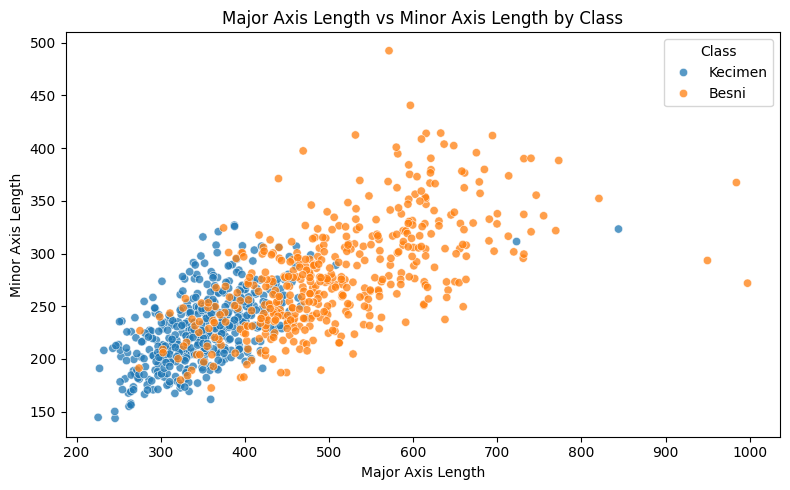

In [25]:
# Plot major and minor axis lengths by class with a scatter plot
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="MajorAxisLength", y="MinorAxisLength", hue="Class", alpha=0.75)
plt.title("Major Axis Length vs Minor Axis Length by Class")
plt.xlabel("Major Axis Length")
plt.ylabel("Minor Axis Length")
plt.tight_layout()
plt.show()

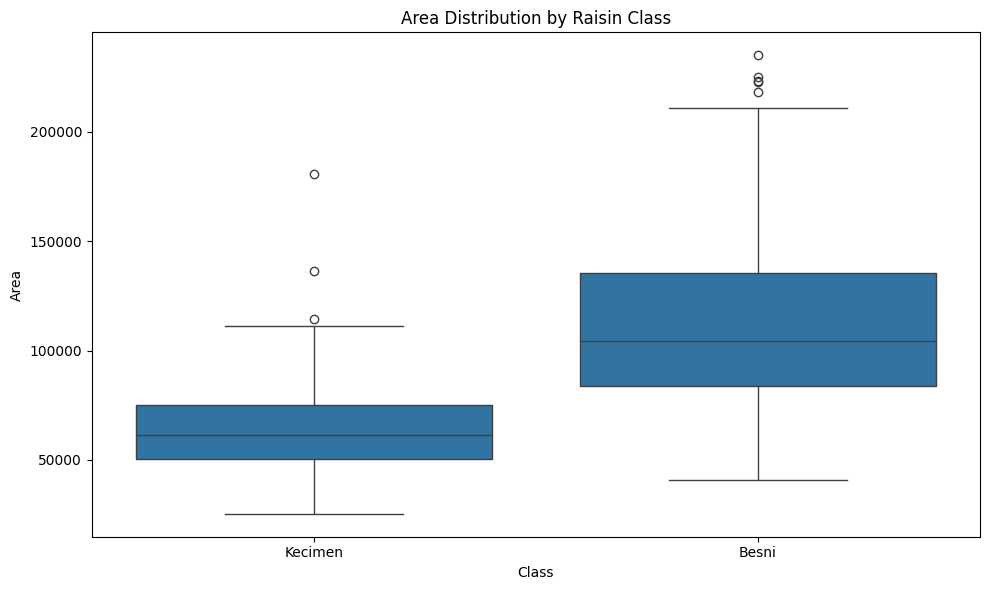

In [26]:
# Compare area distributions across classes with a box plot
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="Class", y="Area")
plt.title("Area Distribution by Raisin Class")
plt.xlabel("Class")
plt.ylabel("Area")
plt.tight_layout()
plt.show()

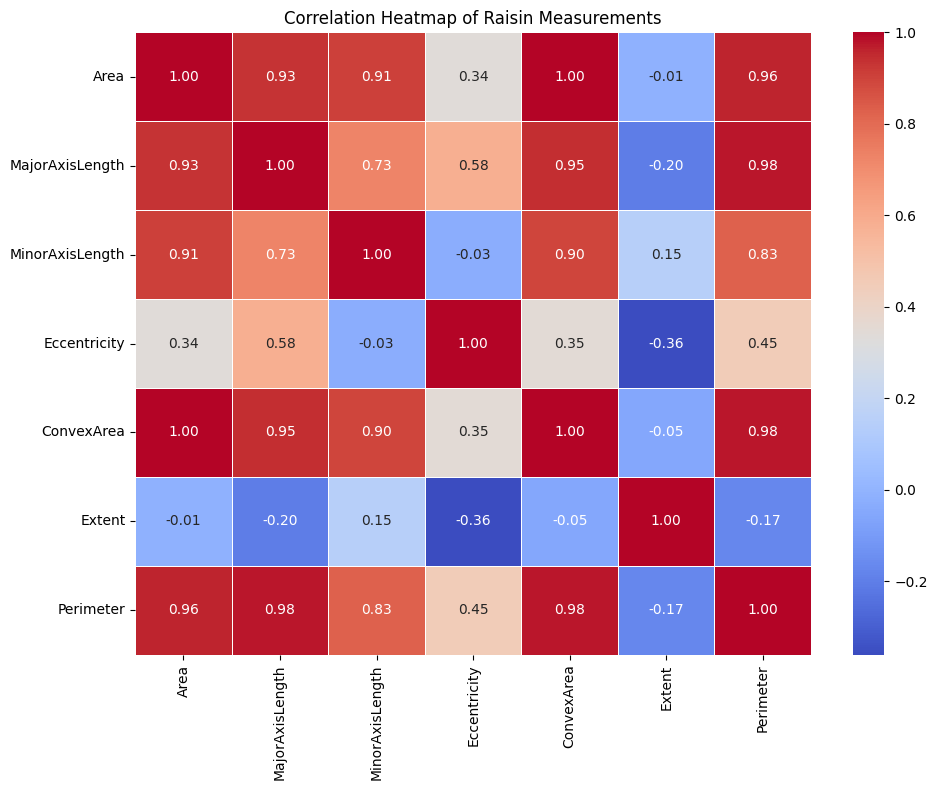

In [27]:
# Visualize correlations between numeric raisin measurements with a heatmap
numeric_data = df.select_dtypes(include=np.number).drop(columns=["Class_encoded"], errors="ignore")
plt.figure(figsize=(10, 8))
sns.heatmap(numeric_data.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Raisin Measurements")
plt.tight_layout()
plt.show()

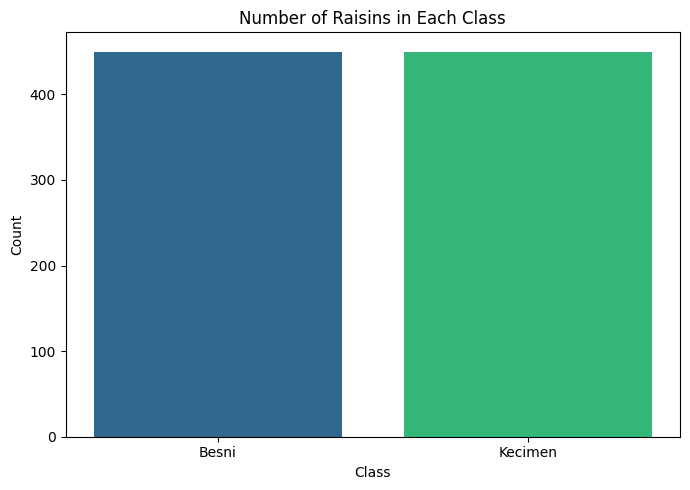

In [28]:
# Show the number of raisin samples in each class with a bar plot
class_counts = df["Class"].value_counts().sort_index()
plt.figure(figsize=(7, 5))
plt.bar(class_counts.index, class_counts.values, color=sns.color_palette("viridis", len(class_counts)))
plt.title("Number of Raisins in Each Class")
plt.xlabel("Class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()